In [3]:
import pandas as pd
import numpy as np


In [4]:
data=pd.read_csv("/content/prepared_df (1).csv")

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11991 entries, 0 to 11990
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     11991 non-null  float64
 1   last_evaluation        11991 non-null  float64
 2   number_project         11991 non-null  int64  
 3   average_monthly_hours  11991 non-null  int64  
 4   tenure                 11991 non-null  int64  
 5   work_accident          11991 non-null  int64  
 6   left                   11991 non-null  int64  
 7   promotion_last_5years  11991 non-null  int64  
 8   department             11991 non-null  object 
 9   salary                 11991 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 936.9+ KB


In [6]:
data.head()

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [7]:
data['department'].unique()

array(['sales', 'accounting', 'hr', 'technical', 'support', 'management',
       'IT', 'product_mng', 'marketing', 'RandD'], dtype=object)

In [8]:
data['salary'].unique()

array(['low', 'medium', 'high'], dtype=object)

In [9]:
data.drop(columns=['department','salary'],inplace=True)

**Split My Features from Y(Target)**

In [10]:
data['left'].unique()

array([1, 0])

In [11]:
X=data.drop(columns=['left'])
y=data['left']

**Logistic Regression**

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify=y)

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [15]:
log_reg = LogisticRegression(max_iter=300)

In [16]:
log_reg.fit(X_train,y_train)

LogisticRegression(max_iter=300)

In [17]:
y_log_pred = log_reg.predict(X_test)

In [18]:
print(f"Accuracy ; {accuracy_score(y_test,y_log_pred)}")
print(f"Precision ; {precision_score(y_test,y_log_pred)}")
print(f"Recall ; {recall_score(y_test,y_log_pred)}")
print(f"f1 ; {f1_score(y_test,y_log_pred)}")


Accuracy ; 0.8257607336390163
Precision ; 0.44565217391304346
Recall ; 0.20603015075376885
f1 ; 0.281786941580756


**Naive Bayes**

In [19]:
from sklearn import naive_bayes

In [20]:
gb = naive_bayes.GaussianNB()

In [21]:
gb.fit(X_train,y_train)

GaussianNB()

In [22]:
y_gb_pred = gb.predict(X_test)

In [23]:
print(f"Accuracy ; {accuracy_score(y_test,y_gb_pred)}")
print(f"Precision ; {precision_score(y_test,y_gb_pred)}")
print(f"Recall ; {recall_score(y_test,y_gb_pred)}")
print(f"f1 ; {f1_score(y_test,y_gb_pred)}")

Accuracy ; 0.838682784493539
Precision ; 0.5099818511796733
Recall ; 0.7060301507537688
f1 ; 0.5922023182297155


**Random Forest**

In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

In [25]:
# create/build hyperparameter

parameter_grid = {
    'n_estimators' : [100,150,200],
    'max_depth' : [10,20],
    'criterion' :['gini','entropy']
}

In [26]:
model = RandomForestClassifier(random_state=42)

In [27]:
grid_search = GridSearchCV(estimator=model,param_grid=parameter_grid,scoring='accuracy',cv=5,verbose=2)

In [28]:
grid_search.fit(X_train,y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END .....criterion=gini, max_depth=10, n_estimators=100; total time=   0.6s
[CV] END .....criterion=gini, max_depth=10, n_estimators=100; total time=   0.6s
[CV] END .....criterion=gini, max_depth=10, n_estimators=100; total time=   0.6s
[CV] END .....criterion=gini, max_depth=10, n_estimators=100; total time=   0.6s
[CV] END .....criterion=gini, max_depth=10, n_estimators=100; total time=   0.6s
[CV] END .....criterion=gini, max_depth=10, n_estimators=150; total time=   0.9s
[CV] END .....criterion=gini, max_depth=10, n_estimators=150; total time=   0.9s
[CV] END .....criterion=gini, max_depth=10, n_estimators=150; total time=   0.8s
[CV] END .....criterion=gini, max_depth=10, n_estimators=150; total time=   0.9s
[CV] END .....criterion=gini, max_depth=10, n_estimators=150; total time=   0.9s
[CV] END .....criterion=gini, max_depth=10, n_estimators=200; total time=   1.2s
[CV] END .....criterion=gini, max_depth=10, n_es

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [10, 20],
                         'n_estimators': [100, 150, 200]},
             scoring='accuracy', verbose=2)

In [29]:
grid_search.best_params_

{'criterion': 'gini', 'max_depth': 20, 'n_estimators': 200}

In [30]:
grid_search.best_score_

np.float64(0.9838408625451756)

In [31]:
best_rf_model = grid_search.best_estimator_

In [32]:
best_rf_model.fit(X_train,y_train)

RandomForestClassifier(max_depth=20, n_estimators=200, random_state=42)

In [33]:
y_pred_rf = best_rf_model.predict(X_test)

**Evaluation**

In [34]:
print(f"Accuracy ; {accuracy_score(y_test,y_pred_rf)}")
print(f"Precision ; {precision_score(y_test,y_pred_rf)}")
print(f"Recall ; {recall_score(y_test,y_pred_rf)}")
print(f"f1 ; {f1_score(y_test,y_pred_rf)}")

Accuracy ; 0.9895789912463526
Precision ; 0.9946949602122016
Recall ; 0.9422110552763819
f1 ; 0.967741935483871


**Implementation Step by Step**

Threshold ; 0.5

In [35]:
y_prob = best_rf_model.predict_proba(X_test)

In [36]:
y_prob

array([[0.99478261, 0.00521739],
       [0.91214286, 0.08785714],
       [1.        , 0.        ],
       ...,
       [0.995     , 0.005     ],
       [0.985     , 0.015     ],
       [0.035     , 0.965     ]])

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

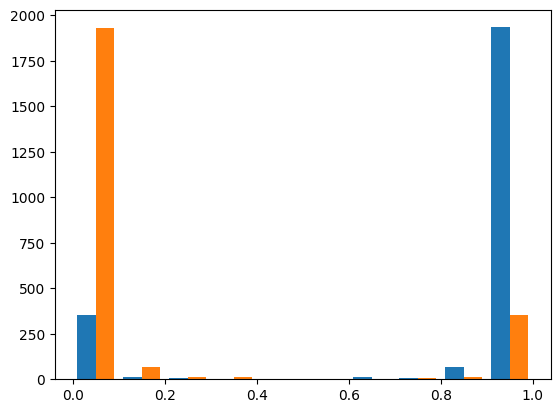

In [38]:
plt.hist(y_prob)
plt.show()

In [39]:
y_prob[:,1]

array([0.00521739, 0.08785714, 0.        , ..., 0.005     , 0.015     ,
       0.965     ])

**Confusion Matrix**

In [40]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

In [41]:
cm = confusion_matrix(y_test,y_pred_rf)
cm

array([[1999,    2],
       [  23,  375]])

In [42]:
cm = confusion_matrix(y_test,y_pred_rf,labels=best_rf_model.classes_)
cm

array([[1999,    2],
       [  23,  375]])

In [43]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=best_rf_model.classes_)


Text(0.5, 1.0, 'Confusion Matrix')

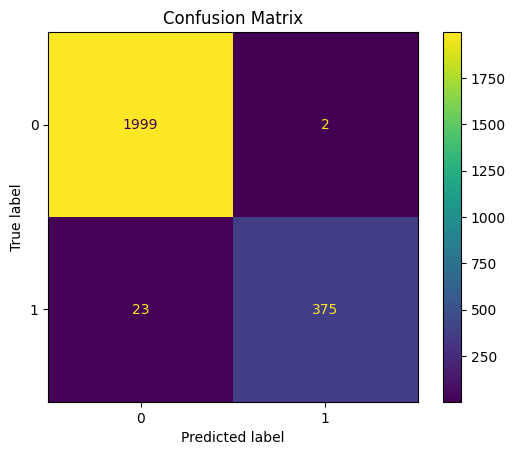

In [44]:
disp.plot()
plt.title("Confusion Matrix")

**Classification Report**

In [45]:
from sklearn.metrics import classification_report

In [46]:
report = classification_report(y_test,y_pred_rf)

In [47]:
print(report)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2001
           1       0.99      0.94      0.97       398

    accuracy                           0.99      2399
   macro avg       0.99      0.97      0.98      2399
weighted avg       0.99      0.99      0.99      2399



**ROC Curve**

In [48]:
from sklearn.metrics import roc_curve,roc_auc_score

In [49]:
y_prob_positive = y_prob[:,1]

In [53]:
fpr, tpr, thresholds = roc_curve(y_test,y_prob_positive)

In [55]:
auc_score = roc_auc_score(y_test,y_prob_positive)

In [56]:
print(auc_score)

0.9877919080660675


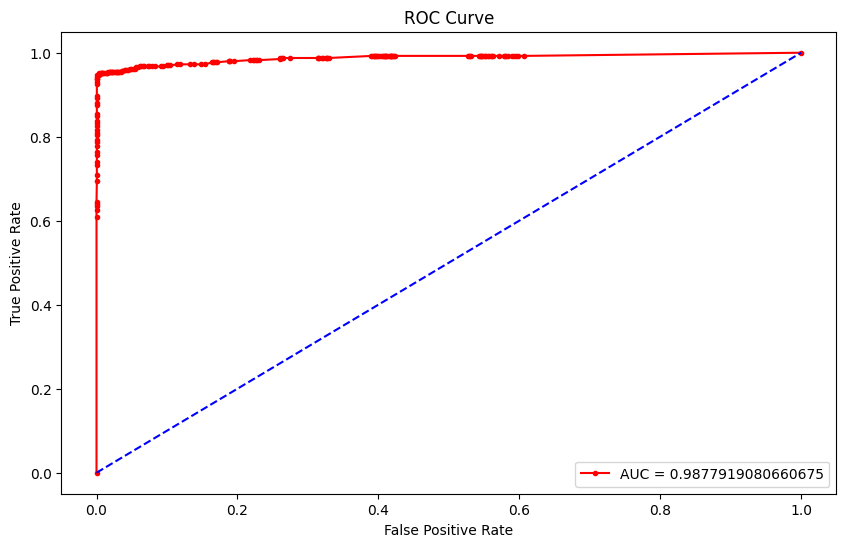

In [57]:
plt.figure(figsize=(10,6))
plt.plot(fpr,tpr,label=f"AUC = {auc_score}",color='red',marker='.')
plt.plot([0,1],[0,1],color='blue',linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

**Threshold Selection**

j - statistic ; finds a balance

In [58]:
tpr - fpr

array([0.        , 0.6080402 , 0.62562814, 0.63567839, 0.64070352,
       0.64572864, 0.69296759, 0.70804296, 0.73316859, 0.73819372,
       0.75578166, 0.76331935, 0.77839472, 0.78593241, 0.79095754,
       0.80352035, 0.80854548, 0.81608316, 0.82613342, 0.83115854,
       0.83618367, 0.84874648, 0.85377161, 0.87387211, 0.87889723,
       0.89146005, 0.89648517, 0.92412337, 0.92914849, 0.93668618,
       0.93618643, 0.94121156, 0.94623668, 0.94423768, 0.94926281,
       0.94626431, 0.9452648 , 0.94476505, 0.94376555, 0.94276605,
       0.94176655, 0.9392678 , 0.93776855, 0.9372688 , 0.93878187,
       0.93728261, 0.93628311, 0.93528361, 0.93478386, 0.93278486,
       0.93228511, 0.93128561, 0.93028611, 0.92778736, 0.92678786,
       0.92628811, 0.92478886, 0.92428911, 0.92229011, 0.92029111,
       0.92180417, 0.92130442, 0.91981898, 0.91881948, 0.91582098,
       0.91532123, 0.91433555, 0.91333605, 0.91033754, 0.90833854,
       0.90885211, 0.90635336, 0.90536767, 0.90386842, 0.90136

In [59]:
np.argmax(tpr - fpr)

np.int64(34)

In [60]:
optimal_index = np.argmax(tpr - fpr)

In [63]:
optimal_threshold = thresholds[optimal_index]
optimal_threshold

np.float64(0.35)

In [65]:
y_pred_new_threshold = (y_prob_positive >= optimal_threshold).astype(int)

In [66]:
cr = classification_report(y_test,y_pred_new_threshold)
print(cr)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2001
           1       0.98      0.95      0.97       398

    accuracy                           0.99      2399
   macro avg       0.99      0.97      0.98      2399
weighted avg       0.99      0.99      0.99      2399

